In [5]:
### Placement Dataset Loading

In [7]:
import pandas as pd

# Load the placement dataset
df = pd.read_csv('/Placement.csv')

# Display the loaded dataset
display(df.head())

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57
5,7.89,2.99
6,6.73,2.60
7,6.75,2.48
8,6.09,2.31
9,8.31,3.51


In [10]:
df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


In [11]:
df.tail()

,cgpa,package
14,7.73,3.42
15,7.25,3.23
16,6.84,2.35
17,5.38,2.09
18,6.94,2.98


In [13]:
df.shape

(19, 2)

In [14]:
df.size

38

In [15]:
df.ndim

2

In [111]:
import pandas as pd
import numpy as np

# 1. Read the existing 19 rows from the file
try:
    df_orig = pd.read_csv('/Placement.csv')
except FileNotFoundError:
    # Fallback to create it if it was temporary
    df_orig = pd.DataFrame({
        'cgpa': [6.89, 5.12, 7.82, 7.42, 6.94, 7.89, 6.73, 6.75, 6.09, 8.31, 5.32, 6.61, 8.94, 6.93, 7.73, 7.25, 6.84, 5.38, 6.94],
        'package': [3.26, 1.98, 3.25, 3.67, 3.57, 2.99, 2.60, 2.48, 2.31, 3.51, 1.86, 2.60, 3.65, 2.89, 3.42, 3.23, 2.35, 2.09, 2.98]
    })

# Standardize column names (strip trailing spaces)
df_orig.columns = df_orig.columns.str.strip()

# Ensure original has placement
if 'placement' not in df_orig.columns:
    df_orig['placement'] = (df_orig['cgpa'] > 6.0).astype(int)

# 2. Add unneeded columns to the original dataset if they don't exist
if 'student_id' not in df_orig.columns:
    df_orig['student_id'] = [f"STU_{100 + i}" for i in range(len(df_orig))]
if 'unnecessary_noise' not in df_orig.columns:
    df_orig['unnecessary_noise'] = np.random.uniform(10, 100, len(df_orig))
if 'constant_val' not in df_orig.columns:
    df_orig['constant_val'] = "Constant_Value"

# 3. Generate 50 new rows with outliers and random variation (NO missing values)
np.random.seed(42)
new_cgpa = np.round(np.random.uniform(5.0, 9.5, 50), 2)
new_package = np.round(new_cgpa * 0.4 + np.random.normal(0, 0.3, 50), 2)
new_placement = (new_cgpa > 6.2).astype(int)

# Create a DataFrame for the 50 new rows
df_new = pd.DataFrame({
    'cgpa': new_cgpa,
    'package': new_package,
    'placement': new_placement,
    'student_id': [f"STU_{100 + len(df_orig) + i}" for i in range(50)],
    'unnecessary_noise': np.random.uniform(10, 100, 50),
    'constant_val': "Constant_Value"
})

# Introduce Outliers (but keep them valid numbers with NO NaNs)
df_new.loc[2, 'cgpa'] = 19.5
df_new.loc[12, 'cgpa'] = 4.5
df_new.loc[22, 'package'] = 15.0
df_new.loc[32, 'package'] = 1.0

# 4. Concatenate original and new data
df_augmented = pd.concat([df_orig, df_new], ignore_index=True)

# Save the clean augmented dataset back to /Placement.csv
df_augmented.to_csv('/Placement.csv', index=False)

# Reload the updated dataset into global df
df = pd.read_csv('/Placement.csv')
print(f"Successfully updated /Placement.csv without any missing values! New shape: {df.shape}")

Successfully updated /Placement.csv without any missing values! New shape: (269, 6)


In [112]:
# Load the augmented dataset and print its information
df_augmented = pd.read_csv('/Placement.csv')
display(df_augmented.info())
display(df_augmented.head(25))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 269 entries, 0 to 268
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   cgpa               249 non-null    float64
 1   package            249 non-null    float64
 2   student_id         269 non-null    object 
 3   unnecessary_noise  269 non-null    float64
 4   constant_val       269 non-null    object 
 5   placement          269 non-null    int64  
dtypes: float64(3), int64(1), object(2)
memory usage: 12.7+ KB


None

,cgpa,package,student_id,unnecessary_noise,constant_val,placement
0,6.89,3.26,STU_100,35.269513,Constant_Value,1
1,5.12,1.98,STU_101,12.188437,Constant_Value,0
2,7.82,3.25,STU_102,68.092507,Constant_Value,1
3,7.42,3.67,STU_103,25.939961,Constant_Value,1
4,6.94,3.57,STU_104,94.641273,Constant_Value,1
5,7.89,2.99,STU_105,95.853572,Constant_Value,1
6,6.73,2.60,STU_106,92.337795,Constant_Value,1
7,6.75,2.48,STU_107,43.314283,Constant_Value,1
8,6.09,2.31,STU_108,11.391095,Constant_Value,1
9,8.31,3.51,STU_109,93.548671,Constant_Value,1


In [113]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 269 entries, 0 to 268
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   cgpa               249 non-null    float64
 1   package            249 non-null    float64
 2   student_id         269 non-null    object 
 3   unnecessary_noise  269 non-null    float64
 4   constant_val       269 non-null    object 
 5   placement          269 non-null    int64  
dtypes: float64(3), int64(1), object(2)
memory usage: 12.7+ KB


In [115]:
df = df.iloc[:, [0, 1]]

In [114]:
df.head()

,cgpa,package,student_id,unnecessary_noise,constant_val,placement
0,6.89,3.26,STU_100,35.269513,Constant_Value,1
1,5.12,1.98,STU_101,12.188437,Constant_Value,0
2,7.82,3.25,STU_102,68.092507,Constant_Value,1
3,7.42,3.67,STU_103,25.939961,Constant_Value,1
4,6.94,3.57,STU_104,94.641273,Constant_Value,1


In [116]:
import matplotlib.pyplot as plt


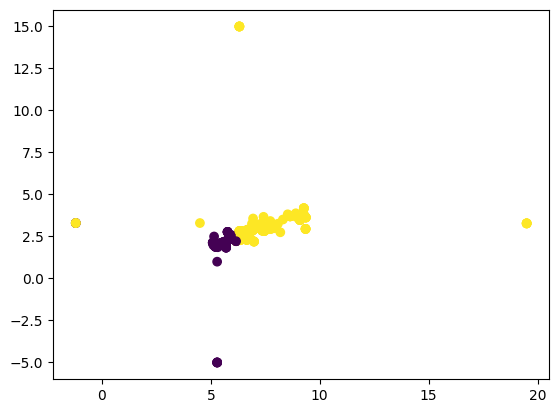

In [117]:
import matplotlib.pyplot as plt
# Re-load the full dataset to ensure 'placement' and other required columns exist
df_full = pd.read_csv('/Placement.csv')

# Plot CGPA vs Package and color by placement status
plt.scatter(df_full['cgpa'], df_full['package'],c=df_full['placement'])


In [118]:
x=df.iloc[:,0:2]
y=df.iloc[:,-1]


In [119]:
x

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57
...,...,...
264,7.98,3.04
265,6.40,2.83
266,7.34,3.03
267,7.46,2.83


In [120]:
y

,package
0,3.26
1,1.98
2,3.25
3,3.67
4,3.57
...,...
264,3.04
265,2.83
266,3.03
267,2.83


In [121]:
from sklearn.model_selection import train_test_split
x_train, x_test , y_train , y_test = train_test_split(x,y,test_size=0.1)

In [122]:
x_train

,cgpa,package
40,NaN,NaN
99,7.73,3.20
253,9.35,2.95
249,7.73,3.20
171,19.50,3.28
...,...,...
267,7.46,2.83
146,7.31,3.23
251,5.29,1.00
147,7.67,3.18


In [123]:
x_test

,cgpa,package
197,7.67,3.18
93,7.05,3.06
6,6.73,2.60
167,7.46,2.83
90,NaN,NaN
121,19.50,3.28
170,9.28,3.76
228,8.19,2.75
192,6.65,2.30
58,6.98,2.20


In [124]:
y_train

,package
40,NaN
99,3.20
253,2.95
249,3.20
171,3.28
...,...
267,2.83
146,3.23
251,1.00
147,3.18


In [125]:
y_test

,package
197,3.18
93,3.06
6,2.60
167,2.83
90,NaN
121,3.28
170,3.76
228,2.75
192,2.30
58,2.20


In [126]:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)


In [127]:
x_train

,cgpa,package
40,NaN,NaN
99,7.73,3.20
253,9.35,2.95
249,7.73,3.20
171,19.50,3.28
...,...,...
267,7.46,2.83
146,7.31,3.23
251,5.29,1.00
147,7.67,3.18


In [128]:
x_test

,cgpa,package
197,7.67,3.18
93,7.05,3.06
6,6.73,2.60
167,7.46,2.83
90,NaN,NaN
121,19.50,3.28
170,9.28,3.76
228,8.19,2.75
192,6.65,2.30
58,6.98,2.20


### Train Logistic Regression with Clean Dataset (No NaNs)

We will reload our clean `/Placement.csv` dataset, extract the features and target variable, split them into training and testing sets, apply feature scaling, and fit our `LogisticRegression` model.

In [139]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Reload the fully clean dataset from /Placement.csv and drop NaNs
df_clean = pd.read_csv('/Placement.csv').dropna()

# 2. Extract Features (cgpa, package) and Target (placement)
X = df_clean[['cgpa', 'package']]
y = df_clean['placement']

# 3. Perform Train-Test Split (90% Train, 10% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

# 4. Standardize the Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Initialize and fit the Logistic Regression model
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

# 6. Evaluate and print model performance using accuracy_score
y_pred = model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
print(f"Dataset Size: {df_clean.shape[0]} rows (after dropping NaNs)")
print(f"Model fitted successfully! Accuracy on test set: {accuracy * 100:.2f}%")

Dataset Size: 233 rows (after dropping NaNs)
Model fitted successfully! Accuracy on test set: 83.33%
